In [ ]:
!pip install rasterio folium

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import rasterio
from rasterio.enums import Resampling

path = "/content/drive/MyDrive/jezero_dem.tif"

with rasterio.open(path) as src:
    print("Original size:", src.width, "x", src.height)
    print("Pixel size:", src.res)
    print("CRS:", src.crs)

    f = 20   # downsample factor (1.8 GB file, so perusa vechuko)
    dem = src.read(1, out_shape=(src.height // f, src.width // f),
                   resampling=Resampling.average).astype(float)
    res = src.res[0] * f
    nodata = src.nodata

if nodata is not None:
    dem[dem == nodata] = np.nan
    dem = np.nan_to_num(dem, nan=np.nanmean(dem))

print("DEM shape:", dem.shape, "| res (m):", res)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Original size: 21400 x 21488
Pixel size: (1.0, 1.0)
CRS: ESRI:103885
DEM shape: (1074, 1070) | res (m): 20.0


In [ ]:
import numpy as np
import rasterio
from rasterio.enums import Resampling
from scipy.ndimage import binary_dilation

path = "/content/drive/MyDrive/jezero_dem.tif"
f = 20

with rasterio.open(path) as src:
    dem = src.read(1, out_shape=(src.height // f, src.width // f),
                   resampling=Resampling.average).astype(float)
    res = src.res[0] * f
    nodata = src.nodata

invalid = np.isnan(dem)
if nodata is not None:
    invalid |= (dem == nodata)
invalid |= (dem < -1e5)          # very low fill values

dem[invalid] = np.nanmean(dem[~invalid])
invalid_big = binary_dilation(invalid, iterations=3)   # edge artifacts ah cover panna

print(dem.shape, res, "| invalid %:", round(invalid.mean()*100, 1))

(1074, 1070) 20.0 | invalid %: 33.7


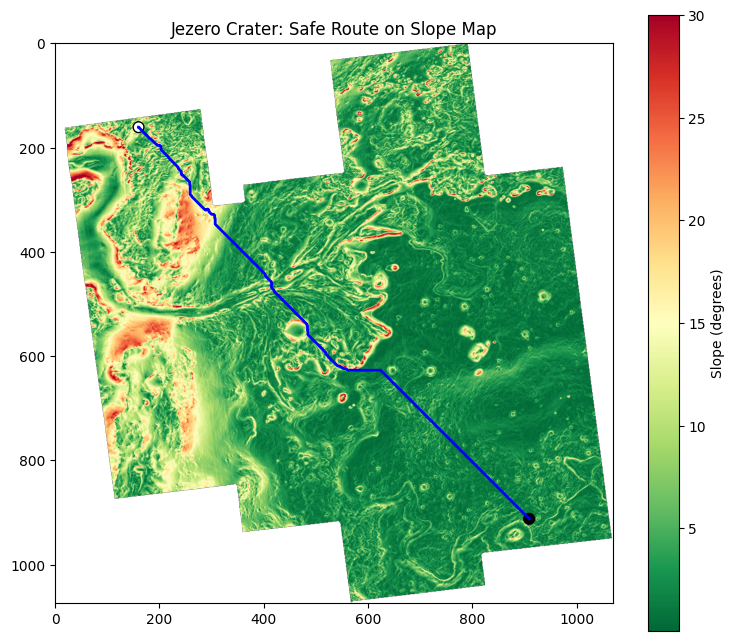

Max slope: 44.1
Distance (km): 16.9
Walking time (hrs at 3 km/h): 5.6


In [ ]:
import matplotlib.pyplot as plt
from skimage.graph import route_through_array

# 1. Slope
dy, dx = np.gradient(dem, res)
slope = np.degrees(np.arctan(np.hypot(dx, dy)))

# 2. Cost map
cost = np.ones_like(slope)
cost[slope > 15] = 10
cost[slope > 25] = 1e6
cost[invalid_big] = 1e6       # data illaadha area = no-go
slope[invalid_big] = np.nan   # plot clean ah theriyum

# 3. Start / end (valid edathula automatic ah)
valid = ~invalid_big
def nearest_valid(r, c):
    rr, cc = np.where(valid)
    i = np.argmin((rr - r)**2 + (cc - c)**2)
    return (int(rr[i]), int(cc[i]))

h, w = dem.shape
start = nearest_valid(int(h * 0.15), int(w * 0.15))
end   = nearest_valid(int(h * 0.85), int(w * 0.85))

# 4. Route
path, total = route_through_array(cost, start, end, fully_connected=True, geometric=True)

# 5. Plot
rows, cols = zip(*path)
plt.figure(figsize=(9, 8))
plt.imshow(slope, cmap="RdYlGn_r", vmax=30)
plt.colorbar(label="Slope (degrees)")
plt.plot(cols, rows, "b-", linewidth=2)
plt.scatter([start[1], end[1]], [start[0], end[0]], c=["white", "black"], s=60, edgecolors="k")
plt.title("Jezero Crater: Safe Route on Slope Map")
plt.show()

# 6. Stats
dist_km = len(path) * res / 1000
print("Max slope:", round(np.nanmax(slope), 1))
print("Distance (km):", round(dist_km, 1))
print("Walking time (hrs at 3 km/h):", round(dist_km / 3, 1))

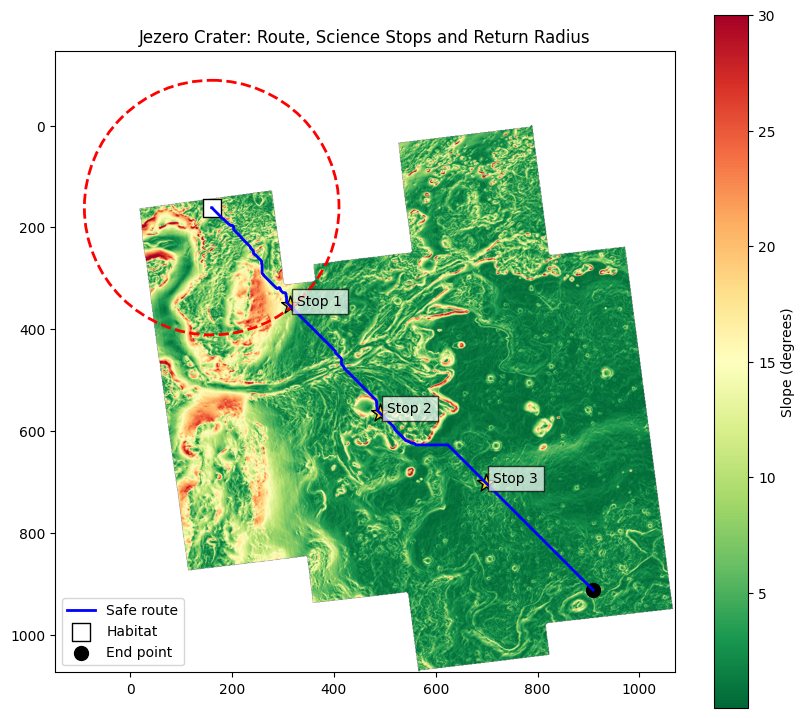

Stop 1: 4.9 km from habitat | elevation -2298 m | slope 8.9 deg
Stop 2: 10.4 km from habitat | elevation -2456 m | slope 2.7 deg
Stop 3: 15.2 km from habitat | elevation -2584 m | slope 6.7 deg


In [ ]:
# --- Science stops (route la 3 points) ---
n = len(path)
stop_idx = [int(n * 0.25), int(n * 0.50), int(n * 0.75)]
stops = [path[i] for i in stop_idx]
stop_names = ["Stop 1", "Stop 2", "Stop 3"]

# --- Return radius (habitat = start) ---
radius_km = 5
radius_px = radius_km * 1000 / res

# --- Plot ---
plt.figure(figsize=(10, 9))
plt.imshow(slope, cmap="RdYlGn_r", vmax=30)
plt.colorbar(label="Slope (degrees)")
plt.plot(cols, rows, "b-", linewidth=2, label="Safe route")

# habitat and end
plt.scatter(start[1], start[0], c="white", s=150, edgecolors="k", marker="s", label="Habitat")
plt.scatter(end[1], end[0], c="black", s=100, label="End point")

# science stops
for (r, c), name in zip(stops, stop_names):
    plt.scatter(c, r, c="gold", s=180, edgecolors="k", marker="*")
    plt.text(c + 15, r, name, fontsize=10, color="black",
             bbox=dict(facecolor="white", alpha=0.7))

# return radius circle
circle = plt.Circle((start[1], start[0]), radius_px, fill=False,
                    color="red", linestyle="--", linewidth=2)
plt.gca().add_patch(circle)

plt.title("Jezero Crater: Route, Science Stops and Return Radius")
plt.legend(loc="lower left")
plt.savefig("jezero_route_map.png", dpi=200, bbox_inches="tight")
plt.show()

# --- Stats ---
for (r, c), name in zip(stops, stop_names):
    d = np.hypot(r - start[0], c - start[1]) * res / 1000
    print(f"{name}: {d:.1f} km from habitat | elevation {dem[r, c]:.0f} m | slope {slope[r, c]:.1f} deg")

In [ ]:
import folium
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

h, w = dem.shape

# --- Layer images (RGBA, data illaadha edam transparent) ---
def make_layer(arr, cmap, vmin, vmax):
    rgba = plt.get_cmap(cmap)(Normalize(vmin, vmax)(arr))
    rgba[invalid_big, 3] = 0
    return (rgba * 255).astype(np.uint8)

slope_img = make_layer(np.nan_to_num(slope), "RdYlGn_r", 0, 30)
elev_img  = make_layer(dem, "terrain", np.percentile(dem[~invalid_big], 1),
                                       np.percentile(dem[~invalid_big], 99))

bounds = [[0, 0], [h, w]]
def xy(r, c):               # image (row, col) -> map (y, x)
    return [h - r, c]

# --- Map ---
m = folium.Map(location=[h / 2, w / 2], zoom_start=-1, min_zoom=-3, max_zoom=3,
               crs="Simple", tiles=None)

# Layer 1: Slope
folium.raster_layers.ImageOverlay(slope_img, bounds=bounds, name="Slope (hazard)",
                                  opacity=0.9).add_to(m)
# Layer 2: Elevation
folium.raster_layers.ImageOverlay(elev_img, bounds=bounds, name="Elevation",
                                  opacity=0.9, show=False).add_to(m)

# Layer 3: Safe route
route_layer = folium.FeatureGroup(name="Safe route")
folium.PolyLine([xy(r, c) for r, c in path[::5]], color="blue", weight=4,
                tooltip=f"Safe route: {dist_km:.1f} km, {dist_km/3:.1f} hrs").add_to(route_layer)
route_layer.add_to(m)

# Layer 4: Habitat + end point
base_layer = folium.FeatureGroup(name="Habitat and end point")
folium.Marker(xy(*start), tooltip="Habitat (start)",
              icon=folium.Icon(color="green", icon="home")).add_to(base_layer)
folium.Marker(xy(*end), tooltip="End point",
              icon=folium.Icon(color="black", icon="flag")).add_to(base_layer)
base_layer.add_to(m)

# Layer 5: Science stops
stop_layer = folium.FeatureGroup(name="Science stops")
for (r, c), name in zip(stops, stop_names):
    d = np.hypot(r - start[0], c - start[1]) * res / 1000
    info = f"<b>{name}</b><br>{d:.1f} km from habitat<br>Elevation: {dem[r, c]:.0f} m<br>Slope: {slope[r, c]:.1f} deg"
    folium.Marker(xy(r, c), popup=folium.Popup(info, max_width=220), tooltip=name,
                  icon=folium.Icon(color="orange", icon="star")).add_to(stop_layer)
stop_layer.add_to(m)

# Layer 6: Return radius (circle ah polygon ah varaiyaren)
radius_px = 5 * 1000 / res
theta = np.linspace(0, 2 * np.pi, 120)
circle_pts = [[h - (start[0] + radius_px * np.sin(t)), start[1] + radius_px * np.cos(t)] for t in theta]
ret_layer = folium.FeatureGroup(name="5 km return radius")
folium.PolyLine(circle_pts, color="red", weight=3, dash_array="8",
                tooltip="5 km emergency return radius").add_to(ret_layer)
ret_layer.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)

m.save("jezero_map.html")
m

# Download
from google.colab import files
files.download("jezero_map.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Landing Site (Habitat): pixel (664, 675) | snapped by 0.0 km
Western Delta Deposit: pixel (462, 402) | snapped by 0.0 km
Western Inflow Channel: pixel (237, 26) | snapped by 0.5 km
Total distance (km): 14.8 | time (hrs at 3 km/h): 4.9


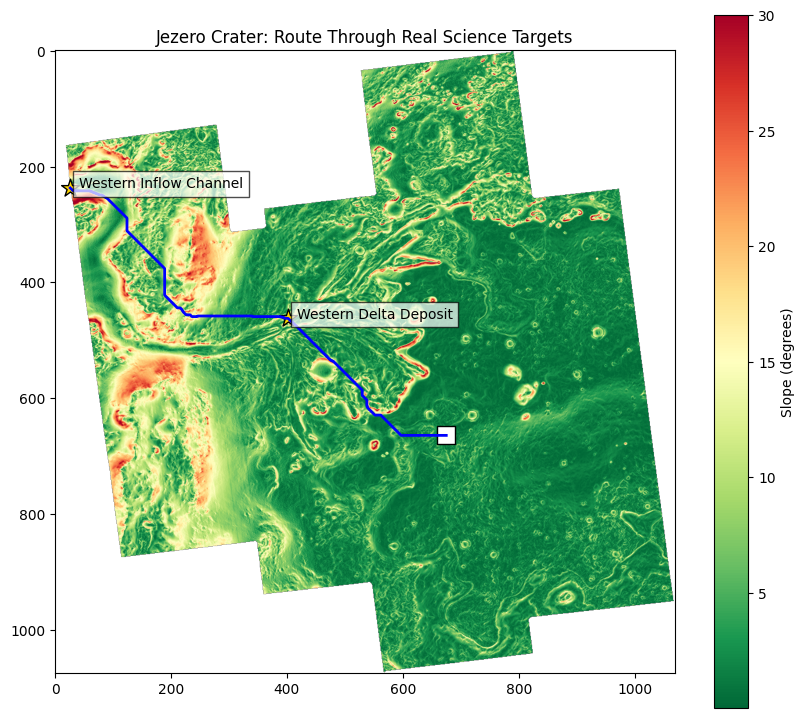

In [ ]:
import pyproj, rasterio
import numpy as np
import matplotlib.pyplot as plt
from skimage.graph import route_through_array

# Habitat la irundhu nearest to farthest
sites = [
    ("Landing Site (Habitat)", 18.445, 77.451),
    ("Western Delta Deposit",  18.5133, 77.3588),
    ("Western Inflow Channel", 18.5874, 77.1995),
]

with rasterio.open("/content/drive/MyDrive/jezero_dem.tif") as src:
    mars_crs = pyproj.CRS.from_wkt(src.crs.to_wkt())
    tf = pyproj.Transformer.from_crs(mars_crs.geodetic_crs, mars_crs, always_xy=True)
    pts = []
    for name, lat, lon in sites:
        x, y = tf.transform(lon, lat)
        r, c = src.index(x, y)
        r = int(np.clip(r // f, 0, dem.shape[0] - 1))
        c = int(np.clip(c // f, 0, dem.shape[1] - 1))
        r2, c2 = nearest_valid(r, c)          # valid DEM pixel ku snap
        moved = np.hypot(r2 - r, c2 - c) * res / 1000
        print(f"{name}: pixel ({r2}, {c2}) | snapped by {moved:.1f} km")
        pts.append((name, (r2, c2)))

names  = [p[0] for p in pts]
coords = [p[1] for p in pts]
start, end = coords[0], coords[-1]
stops, stop_names = coords[1:], names[1:]

# Route: habitat -> delta -> inflow channel
path = []
for a, b in zip(coords[:-1], coords[1:]):
    seg, _ = route_through_array(cost, a, b, fully_connected=True, geometric=True)
    path += seg

rows, cols = zip(*path)
dist_km = len(path) * res / 1000
print("Total distance (km):", round(dist_km, 1), "| time (hrs at 3 km/h):", round(dist_km / 3, 1))

# Plot
plt.figure(figsize=(10, 9))
plt.imshow(slope, cmap="RdYlGn_r", vmax=30)
plt.colorbar(label="Slope (degrees)")
plt.plot(cols, rows, "b-", linewidth=2)
plt.scatter(start[1], start[0], c="white", s=150, edgecolors="k", marker="s")
for (r, c), n in zip(stops, stop_names):
    plt.scatter(c, r, c="gold", s=180, edgecolors="k", marker="*")
    plt.text(c + 15, r, n, bbox=dict(facecolor="white", alpha=0.7))
plt.title("Jezero Crater: Route Through Real Science Targets")
plt.savefig("jezero_route_real.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
legs = list(zip(coords[:-1], coords[1:]))
for (a, b), n in zip(legs, stop_names):
    seg, _ = route_through_array(cost, a, b, fully_connected=True, geometric=True)
    rr, cc = zip(*seg)
    s = slope[rr, cc]
    d = len(seg) * res / 1000
    print(f"Habitat/prev -> {n}: {d:.1f} km | {d/3:.1f} hrs | max slope on path {np.nanmax(s):.1f} deg | mean {np.nanmean(s):.1f} deg")

for (r, c), n in zip(stops, stop_names):
    print(f"{n}: elevation {dem[r, c]:.0f} m | slope {slope[r, c]:.1f} deg")

Habitat/prev -> Western Delta Deposit: 5.9 km | 2.0 hrs | max slope on path 14.7 deg | mean 4.8 deg
Habitat/prev -> Western Inflow Channel: 8.9 km | 3.0 hrs | max slope on path 15.0 deg | mean 8.0 deg
Western Delta Deposit: elevation -2428 m | slope 9.3 deg
Western Inflow Channel: elevation -2291 m | slope 7.2 deg


In [24]:
import folium
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

h, w = dem.shape

# --- Layer images (RGBA, data illaadha edam transparent) ---
def make_layer(arr, cmap, vmin, vmax):
    rgba = plt.get_cmap(cmap)(Normalize(vmin, vmax)(arr))
    rgba[invalid_big, 3] = 0
    return (rgba * 255).astype(np.uint8)

slope_img = make_layer(np.nan_to_num(slope), "RdYlGn_r", 0, 30)
elev_img  = make_layer(dem, "terrain", np.percentile(dem[~invalid_big], 1),
                                       np.percentile(dem[~invalid_big], 99))

bounds = [[0, 0], [h, w]]
def xy(r, c):               # image (row, col) -> map (y, x)
    return [h - r, c]

# --- Map ---
m = folium.Map(location=[h / 2, w / 2], zoom_start=-1, min_zoom=-3, max_zoom=3,
               crs="Simple", tiles=None)

# Layer 1: Slope
folium.raster_layers.ImageOverlay(slope_img, bounds=bounds, name="Slope (hazard)",
                                  opacity=0.9).add_to(m)
# Layer 2: Elevation
folium.raster_layers.ImageOverlay(elev_img, bounds=bounds, name="Elevation",
                                  opacity=0.9, show=False).add_to(m)

# Layer 3: Safe route
route_layer = folium.FeatureGroup(name="Safe route")
folium.PolyLine([xy(r, c) for r, c in path[::5]], color="blue", weight=4,
                tooltip=f"Safe route: {dist_km:.1f} km, {dist_km/3:.1f} hrs").add_to(route_layer)
route_layer.add_to(m)

# Layer 4: Habitat + end point
base_layer = folium.FeatureGroup(name="Habitat and end point")
folium.Marker(xy(*start), tooltip="Habitat (start)",
              icon=folium.Icon(color="green", icon="home")).add_to(base_layer)
folium.Marker(xy(*end), tooltip="End point",
              icon=folium.Icon(color="black", icon="flag")).add_to(base_layer)
base_layer.add_to(m)

# Layer 5: Science stops
stop_layer = folium.FeatureGroup(name="Science stops")
for (r, c), name in zip(stops, stop_names):
    d = np.hypot(r - start[0], c - start[1]) * res / 1000
    info = f"<b>{name}</b><br>{d:.1f} km from habitat<br>Elevation: {dem[r, c]:.0f} m<br>Slope: {slope[r, c]:.1f} deg"
    folium.Marker(xy(r, c), popup=folium.Popup(info, max_width=220), tooltip=name,
                  icon=folium.Icon(color="orange", icon="star")).add_to(stop_layer)
stop_layer.add_to(m)

# Layer 6: Return radius (circle ah polygon ah varaiyaren)
radius_px = 5 * 1000 / res
theta = np.linspace(0, 2 * np.pi, 120)
circle_pts = [[h - (start[0] + radius_px * np.sin(t)), start[1] + radius_px * np.cos(t)] for t in theta]
ret_layer = folium.FeatureGroup(name="5 km return radius")
folium.PolyLine(circle_pts, color="red", weight=3, dash_array="8",
                tooltip="5 km emergency return radius").add_to(ret_layer)
ret_layer.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)

m.save("jezero_map.html")
m

# Download
from google.colab import files
files.download("jezero_map.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
from google.colab import files
files.download("jezero_route_real.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>